<center>
    
## Dinámica de Maquinaria - Parcial 2 - Intento 3
**Camila Uribe - 202217043**
</center>

In [1]:
import sys
!{sys.executable} -m pip install joblib

Defaulting to user installation because normal site-packages is not writeable


In [2]:
import scipy 
import sympy as smp
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML
import os 
import h5py
from tqdm import tqdm
from joblib import Parallel, delayed
import timeit
from sympy import sin, cos, tan, Symbol, symbols, Matrix
from sympy.physics.vector import cross
from sympy.physics.mechanics import dynamicsymbols, ReferenceFrame
from scipy.optimize import fsolve, least_squares
from scipy.optimize import least_squares
from scipy.integrate import odeint
from sympy import symbols, Eq, solve
from scipy.interpolate import interp1d
import matplotlib.animation as animation
from IPython.display import HTML
from matplotlib.gridspec import GridSpec
from scipy.interpolate import CubicSpline
from scipy.optimize import differential_evolution
from scipy.optimize import minimize
from scipy.optimize import Bounds
from scipy.spatial import KDTree

# ---------- Plot style: SciencePlots, paper-ready ----------
import scienceplots
plt.style.use(['science', 'no-latex'])
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.grid'] = False
plt.rcParams['font.size'] = 14
plt.rcParams['axes.titlesize'] = 20
plt.rcParams['axes.labelsize'] = 16
plt.rcParams['xtick.labelsize'] = 14
plt.rcParams['ytick.labelsize'] = 14
plt.rcParams['legend.fontsize'] = 14

<center>

#### Parte 1: Spline


In [3]:
t = symbols('t')
x1s, x2s, x3s, x4s = symbols('x1s, x2s, x3s, x4s')
y1s, y2s, y3s, y4s = symbols('y1s, y2s, y3s, y4s')

listx = [x1s, x2s, x3s, x4s, x1s]
listy = [y1s, y2s, y3s, y4s, y1s]

In [4]:
#EL MIO - SIRVEEEEE
#params_p = {x1s:300/1000, x2s:334.34/1000, x3s:301.87/1000, x4s:273.49/1000, y1s:202.36/1000, y2s:237.71/1000, y3s:213.13/1000, y4s:171.09/1000} 

#### Para probar el bono, recomiendo poner # en el params_p utilizado actualmente, reiniciar el kernel (importante) y quitarle el # a otro. Aquí podrán ver las diferentes curvas propuestas en el doc de spline de la clase y las que logra mi código a partir de estas. Algunas, claramente, encuentran curvas más parecidas a las requeridas que otras, pero, en general todas deberían servir. Aquí hay algunas curvas de la clase que intenté aleatoriamente y todas sirven. Para probar con otros puntos sólo es poner las coordenadas en el orden mostrado y dividir por 1000 (mismo formato)

In [5]:
#params_p = {x1s: 300/1000, x2s: 337.38/1000, x3s: 298.77/1000, x4s: 289.23/1000, y1s: 188.88/1000, y2s: 247.41/1000, y3s: 237.71/1000, y4s: 210.43/1000}  
params_p = {x1s: 300/1000, x2s: 344.59/1000, x3s: 297.93/1000, x4s: 258.97/1000, y1s: 200/1000, y2s: 196.26/1000, y3s: 221.3/1000, y4s: 200/1000}  
#arams_p = {x1s: 300/1000, x2s: 353.8/1000, x3s: 300/1000, x4s: 261.94/1000, y1s: 189.83/1000, y2s: 212.2/1000, y3s: 202.95/1000, y4s: 185.28/1000}
#params_p = {x1s: 300/1000, x2s: 354.48/1000, x3s: 299.1/1000, x4s: 279.54/1000, y1s: 219.98/1000, y2s: 200.94/1000, y3s: 235.78/1000, y4s: 216.52/1000}
#params_p = {x1s: 300/1000, x2s: 320.8/1000, x3s: 296.99/1000, x4s: 283.78/1000, y1s: 205.31/1000, y2s: 216.52/1000, y3s: 264.35/1000, y4s: 216.52/1000}
#params_p = {x1s: 300/1000, x2s: 335.29/1000, x3s: 285.08/1000, x4s: 275.27/1000, y1s: 209.8/1000, y2s: 220.44/1000, y3s: 215.82/1000, y4s: 192.66/1000}
#params_p = {x1s: 300/1000, x2s: 332.58/1000, x3s: 338.94/1000, x4s: 243.65/1000, y1s: 200.57/1000, y2s: 226.4/1000, y3s: 287.26/1000, y4s: 212.87/1000}
#params_p = {x1s: 300/1000, x2s: 355.47/1000, x3s: 300/1000, x4s: 267.86/1000, y1s: 244.4/1000, y2s: 265.48/1000, y3s: 251.3/1000, y4s: 236.28/1000}

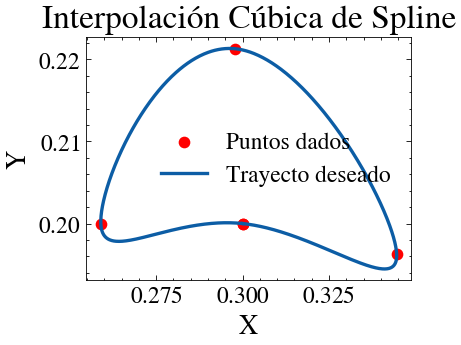

In [6]:
listx_subs = [float(xi.subs(params_p)) for xi in listx]
listy_subs = [float(yi.subs(params_p)) for yi in listy]

cs_x = CubicSpline(range(len(listx_subs)), listx_subs, bc_type='periodic')
cs_y = CubicSpline(range(len(listy_subs)), listy_subs, bc_type='periodic')

t_fine = np.linspace(0, len(listx_subs) - 1, 1000)
x_fine = cs_x(t_fine)
y_fine = cs_y(t_fine)

plt.scatter(listx_subs, listy_subs, color='red', label="Puntos dados") 
plt.plot(x_fine, y_fine, label="Trayecto deseado", linestyle='-', linewidth=2)
plt.legend()
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Interpolación Cúbica de Spline")
plt.grid(False)
plt.show()

In [7]:
dx = np.diff(x_fine)
dy = np.diff(y_fine)
segment_lengths = np.sqrt(dx**2 + dy**2)
arc_length = np.concatenate([[0], np.cumsum(segment_lengths)])

n_samples = 75
arc_pos = np.linspace(0, arc_length[-1], n_samples)

interp_x = interp1d(arc_length, x_fine)
interp_y = interp1d(arc_length, y_fine)

x_ = interp_x(arc_pos)
y_ = interp_y(arc_pos)

evenly_spaced_points = list(zip(x_, y_))

<center>

#### Parte 2: Mecanismo del problema


In [8]:
#Set-up del problema
t = symbols('t')

d1, d2, l1, l2, l12, x2, y2, desf= symbols('d1, d2, l1, l2, l12, x2, y2, desf')
theta, beta, gamma, phi = dynamicsymbols('theta, beta, gamma, phi')

N = ReferenceFrame('N')
A = N.orientnew('A', 'Axis', (theta, N.z))
B = A.orientnew('B', 'Axis', (beta, N.z))
C = B.orientnew('C', 'Axis', (-gamma, N.z))
D = N.orientnew('D', 'Axis', (phi, N.z))

r1 = d1*A.x
r2 = l12*B.x #vector hasta la unión entre las dos barras, no hasta el final de la barra 1 (l1) 
r3 = l2*C.x
r4 = -d2*D.x
r5 = -x2*N.x - y2*N.y 

r6 = (l1)*B.x #la barra 1 (longitud entera)

#params = {d1:0.1, d2:0.05, l1:0.5, l2:0.2, l12:0.35, x2: 0.3, y2:0.1, desf:np.pi/12} #params más parecido
params = {d1:0.15, d2:0.07, l1:0.6, l2:0.25, l12:0.35, x2: 0.3, y2:0.05, desf:np.pi/4}

loop = (r1+r2+r3+r4+r5).express(N)

loopx = loop.dot(N.x).simplify()  
loopy = loop.dot(N.y).simplify()

eq_fun = smp.lambdify( (theta, beta, gamma, phi, d1, d2, l1, l2, l12, x2, y2), [loopx, loopy], "numpy")

In [9]:
def FK(q, params, z0=None):
    eq_fun_fixed = lambda th, be, ga, ph: eq_fun(
        th, be, ga, ph,
        params[d1], params[d2], params[l1], params[l2], 
        params[l12], params[x2], params[y2])

    def fsolve_fun(z):
        return eq_fun_fixed(q[0], z[0], z[1], q[1])

    z0 = [np.deg2rad(80), np.deg2rad(120)] if z0 is None else z0
    out = least_squares(fsolve_fun, z0)

    if not out.success:
        print(f"Warning: FK solver failed at theta={q[0]:.3f}, phi={q[1]:.3f}")
        return None, out
    
    return out.x, out

def components(vector, frame):
    v = [vector.dot(frame.x), vector.dot(frame.y)]
    return v[0], v[1] 

r6_sym = components(r1 + r6, N)
r6_num_func = smp.lambdify([theta, beta, d1, d2, l1, l2, l12, x2, y2], r6_sym, "numpy")

def forward_kinematics(param, num_points=75, rot=None, offset=None):
    w1 = 1
    w2 = 1
    desf_val = param[desf]

    tiempo_1rev_w2 = (2 * np.pi) / abs(w1)
    tiempo = np.linspace(0, float(tiempo_1rev_w2), num_points)
    theta_vals = w1 * tiempo
    phi_vals = w2 * tiempo + desf_val

    beta_list = []
    gamma_list = []
    r6x_vals = []
    r6y_vals = []

    initial_guess = [np.deg2rad(80), np.deg2rad(110)]

    for theta_val, phi_val in zip(theta_vals, phi_vals):
        beta_gamma, _ = FK([theta_val, phi_val], param, initial_guess)
        beta, gamma = beta_gamma
        beta_list.append(beta)
        gamma_list.append(gamma)
        initial_guess = beta_gamma

        r6x, r6y = r6_num_func(
            theta_val, beta,
            param[d1], param[d2], param[l1], param[l2], param[l12], param[x2], param[y2]
        )

        r6x_vals.append(float(r6x))
        r6y_vals.append(float(r6y))

    curve = np.column_stack((r6x_vals, r6y_vals))

    if rot is not None:
        curve = curve @ rot.T

    if offset is not None:
        curve = curve + np.asarray(offset)

    theta_array = np.array(theta_vals)
    beta_array = np.array(beta_list)
    gamma_array = np.array(gamma_list)
    phi_array = np.array(phi_vals)

    return curve, theta_array, beta_array, gamma_array, phi_array

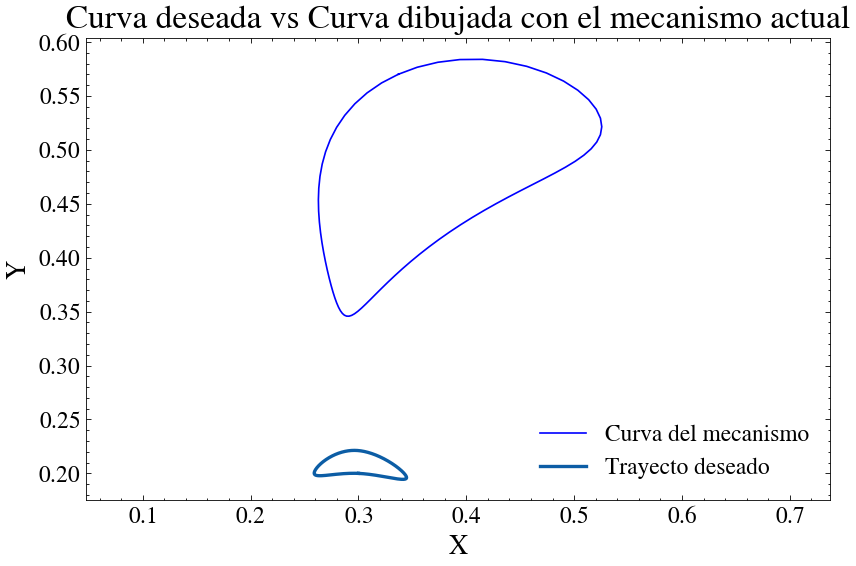

In [10]:
curve, *_ = forward_kinematics(params)
x_vals, y_vals = zip(*curve)

# Plot
plt.figure(figsize=(8, 5))
plt.plot(x_vals, y_vals, label='Curva del mecanismo', color='blue')
plt.plot(x_fine, y_fine, label="Trayecto deseado", linestyle='-', linewidth=2)
#plt.scatter(x_vals[0], y_vals[0], color='red', label='Start Point')
plt.title("Curva deseada vs Curva dibujada con el mecanismo actual")
plt.xlabel("X")
plt.ylabel("Y")
plt.axis('equal')
plt.grid(False)
plt.legend()
plt.show()

In [11]:
def resample_curve_by_arclength(curve_points, num_samples=75):
    x_vals, y_vals = zip(*curve_points)
    
    dx = np.diff(x_vals)
    dy = np.diff(y_vals)
    segment_lengths = np.sqrt(dx**2 + dy**2)
    arc_length = np.concatenate([[0], np.cumsum(segment_lengths)])

    arc_positions = np.linspace(0, arc_length[-1], num_samples)

    interp_x = interp1d(arc_length, x_vals, kind='cubic')
    interp_y = interp1d(arc_length, y_vals, kind='cubic')

    x_resampled = interp_x(arc_positions)
    y_resampled = interp_y(arc_positions)

    return list(zip(x_resampled, y_resampled))

original_curve, *_  = forward_kinematics(params)
even_curve = resample_curve_by_arclength(original_curve, num_samples=75)

<center>

#### Normalizacion de las curvas

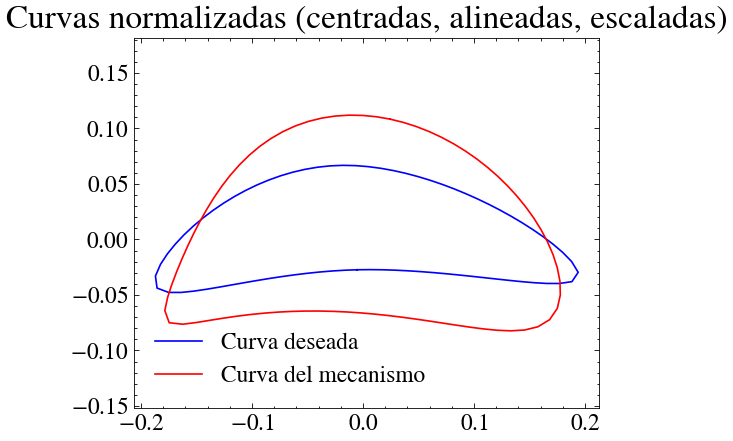

In [12]:
def normalize_curve(curve_points, reference_V=None):
    curve = np.array(curve_points)
    center = curve.mean(axis=0)
    curve_centered = curve - center

    U, S, Vt = np.linalg.svd(curve_centered)
    scale = S[0]
    V = Vt.T 

    if reference_V is not None:
        for i in range(2):
            if np.dot(V[:, i], reference_V[:, i]) < 0:
                V[:, i] *= -1

    if np.linalg.det(V) < 0:
        V[:, 1] *= -1

    curve_normalized = np.dot(curve_centered, V) / scale
    return curve_normalized, center, scale, V


traj_star = evenly_spaced_points
norm_target, center_target, scale_target, V_target = normalize_curve(traj_star)

even_curve_resampled = even_curve
norm_mechanism, center_mech, scale_mech, _ = normalize_curve(even_curve_resampled, reference_V=V_target)

plt.figure(figsize=(5, 4))
plt.plot(norm_target[:, 0], norm_target[:, 1], label="Curva deseada", color="blue")
plt.plot(norm_mechanism[:, 0], norm_mechanism[:, 1], label="Curva del mecanismo", color="red")
plt.title("Curvas normalizadas (centradas, alineadas, escaladas)")
plt.axis("equal")
plt.grid(False)
plt.legend()
plt.show()

<center>

#### Comparación y optimización inicial

In [13]:
mechanism_bounds = {
        "d1":   (0.02, 0.15),    # engranaje 1
        "d2":   (0.02, 0.15),    # engranaje 2
        "l1":   (0.15, 0.40),    # longitud barra 1 
        "l2":   (0.15, 0.40),    # longitud barra 2
        "l12":  (0.05, 0.30),    # bar 1 joint position
        "x2":   (0.05, 0.50),    # gear 2 x-position
        "y2":   (-0.20, 0.20),   # gear 2 y-position
        "desf": (0.0, 2 * np.pi) # phase difference (in radians)
    }

def check_constraints(sample, keys):
    param = dict(zip(keys, sample))

    d1   = param["d1"]
    d2   = param["d2"]
    l1   = param["l1"]
    l2   = param["l2"]
    l12  = param["l12"]
    x2   = param["x2"]
    y2   = param["y2"]
    
    if l12 > l1:
        return False
    if x2 < (d1 + d2):
        return False

    r1 = d1
    r2 = d2
    r3 = l12
    r4 = l2
    r5 = np.sqrt(x2**2 + y2**2)

    bars = sorted([r1, r2, r3, r4, r5])
    rmin1, rmin2, rmid1, rmid2, rmax = bars

    return (rmax + rmin1 + rmin2) < (rmid1 + rmid2)

#### Para mejores curvas se puede aumentar el número de n_samples de 5,000 a 10,000 (por ejemplo). Con esto algunas curvas mejoran bastante, algunas no tanto, pero si incrementa bastante el tiempo en que se demora el código en correr. 

In [14]:
def sample_parameter_space(bounds, n_samples=1000, seed=42):
    np.random.seed(seed)
    
    keys = list(bounds.keys())
    num_params = len(keys)
    valid_samples = []

    max_attempts = 15 * n_samples  

    for _ in range(max_attempts):
        sample = [np.random.uniform(low, high) for (low, high) in bounds.values()]
        
        if check_constraints(sample, keys):
            valid_samples.append(sample)
        
        if len(valid_samples) >= n_samples:
            break

    if len(valid_samples) < n_samples:
        print(f"⚠️ Warning: Only generated {len(valid_samples)} valid samples after {max_attempts} attempts.")

    return np.array(valid_samples), keys

param_samples, param_names = sample_parameter_space(mechanism_bounds, n_samples=10000, seed=42)

#### SÓLO CORRER ESTA PARTE DEL CÓDIGO 1 VEZ (se demora y no se necesita más por que queda guardado aparte)
##### Se debería demorar aprox. 12 minutos¶

In [16]:
def simulate_and_save(params_array, param_names, output_path="mechanism_dataset_2.h5", num_points=75):
    N = params_array.shape[0]
    param_syms = symbols(param_names)

    with h5py.File(output_path, "w") as f:
        f.create_dataset("parameters", shape=(N, 8), dtype="float32")
        f.create_dataset("trajectories", shape=(N, num_points, 2), dtype="float32")

        for i in tqdm(range(N), desc="Simulating trajectories"):
            row = params_array[i]
            param_dict = dict(zip(param_syms, row))

            try:
                raw_curve, *_ = forward_kinematics(param_dict)
                resampled = resample_curve_by_arclength(raw_curve, num_samples=num_points)

                #dist = np.linalg.norm(np.array(resampled[0]) - np.array(resampled[-1]))
                #if dist > 1e-2:
                    #if i % 200 == 0:  # Log only some of them
                            #print(f"[Info] Skipped curve at index {i} — closure dist = {dist:.5f}")
                            #print(f"Params: {param_dict}")
                            #f["parameters"][i, :] = row.astype(np.float32)
                            #f["trajectories"][i, :, :] = np.full((num_points, 2), np.nan, dtype=np.float32)
                            #continue
   
                traj_array = np.array(resampled, dtype=np.float32)
                f["parameters"][i, :] = row.astype(np.float32)
                f["trajectories"][i, :, :] = traj_array

            except Exception as e:
                print(f"⚠️  Error at index {i}: {e}")
                f["parameters"][i, :] = row.astype(np.float32)
                f["trajectories"][i, :, :] = np.full((num_points, 2), np.nan, dtype=np.float32)

    print(f"\n✅ Dataset saved to: {output_path}")

simulate_and_save(param_samples, param_names, output_path="mechanism_dataset_2.h5", num_points=75)

Simulating trajectories: 100%|██████████| 10000/10000 [04:18<00:00, 38.75it/s]


✅ Dataset saved to: mechanism_dataset_2.h5


#### Desde aca correr cada vez 

Comparing curves: 100%|██████████| 10000/10000 [00:06<00:00, 1620.34it/s]



✅ Best match found!
Index: 612
Error: 0.0021411893116200713
Best Parameters:
d1 = 0.08076
d2 = 0.04288
l1 = 0.23608
l2 = 0.26112
l12 = 0.23563
x2 = 0.15233
y2 = -0.00997
desf = 5.12303


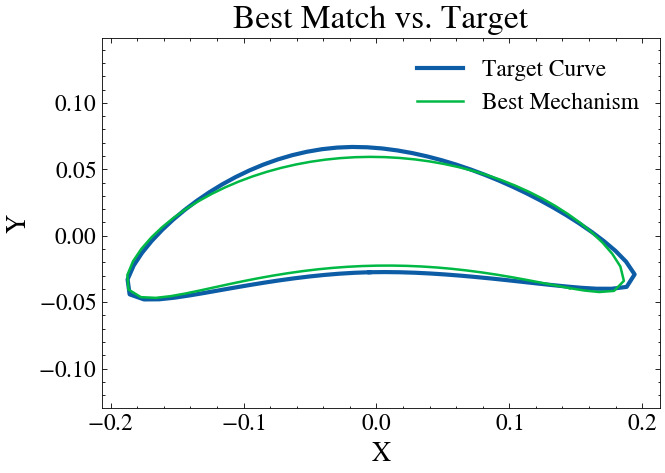

In [15]:
def pointwise_loss_with_shift(curve1, curve2):
    N = len(curve1)
    min_loss = np.inf

    for shift in range(N):
        shifted = np.roll(curve2, shift, axis=0)
        loss = np.sum(np.linalg.norm(curve1 - shifted, axis=1)**2)

        if loss < min_loss:
            min_loss = loss

    return min_loss


def find_best_mechanism(target_curve, h5_path="mechanism_dataset_2.h5"):
    target_curve_resampled = resample_curve_by_arclength(target_curve, num_samples=75)
    norm_target, center, scale, V = normalize_curve(target_curve_resampled)

    with h5py.File(h5_path, "r") as f:
        params = f["parameters"][:]     
        trajs = f["trajectories"][:]

    errors = []
    valid_indices = []

    for i in tqdm(range(trajs.shape[0]), desc="Comparing curves"):
        curve = trajs[i]

        if np.isnan(curve).any():
            errors.append(np.inf)
            continue

        try:
            norm_curve, *_ = normalize_curve(curve, reference_V=V)
            loss = pointwise_loss_with_shift(norm_target, norm_curve)
            errors.append(loss)
            valid_indices.append(i)
        except Exception as e:
            print(f"⚠️ Error at index {i}: {e}")
            errors.append(np.inf)

    errors = np.array(errors)
    best_idx = np.argmin(errors)
    best_error = errors[best_idx]
    best_params = params[best_idx]
    best_curve = trajs[best_idx]

    print("\n✅ Best match found!")
    print("Index:", best_idx)
    print("Error:", best_error)
    print("Best Parameters:")
    for name, value in zip(param_names, best_params):
        print(f"{name} = {value:.5f}")
        
    norm_best_curve, centerx, scalex, vx = normalize_curve(best_curve, reference_V=V)

    plt.figure(figsize=(6, 4))
    plt.plot(*zip(*norm_target), label="Target Curve", linewidth=2.5)
    plt.plot(*zip(*norm_best_curve), label="Best Mechanism", linewidth=1.5)
    plt.title("Best Match vs. Target")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.axis("equal")
    plt.grid(False)
    plt.legend()
    plt.show()

    normalization_info = {
        'center': centerx,
        'scale': scalex,
        'V': vx
    }

    param_syms = symbols(param_names)
    best_params_dict = dict(zip(param_syms, best_params))

    return best_params_dict, best_curve, best_error, normalization_info, norm_best_curve

best_params, best_curve, best_error, normalization_info, norm_curve_final = find_best_mechanism(evenly_spaced_points)

<center>

#### De-normalización de la curva

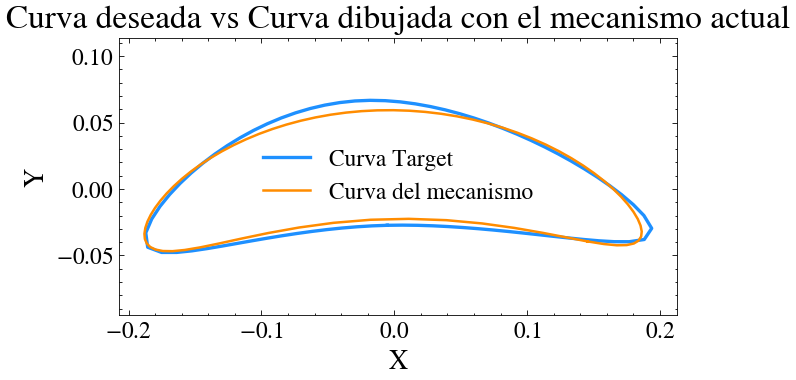

In [16]:
target_norm, target_center, target_scale, target_V = normalize_curve(evenly_spaced_points)
xnorm_vals, ynorm_vals = zip(*target_norm)
    
curve_best_params_fk, *_  = forward_kinematics(best_params)
curve_best_params = resample_curve_by_arclength(curve_best_params_fk)
xb_vals, yb_vals = zip(*curve_best_params)

curve_norm1, center1, scale1, V1 = normalize_curve(curve_best_params, reference_V = target_V)
x1_vals, y1_vals = zip(*curve_norm1)

keys_to_scale = list(best_params.keys())[:7]
scaled_params1 = {k: (v / normalization_info['scale'] if k in keys_to_scale else v) for k, v in best_params.items()}
curve_scaled, *_ = forward_kinematics(scaled_params1)
curve_scaled1 = np.array(resample_curve_by_arclength(curve_scaled))
xs_vals, ys_vals = zip(*curve_scaled1)

center_scaled = normalization_info['V'].T @ (-1*curve_scaled1.mean(axis=0))
curve_transformed1, *_  = forward_kinematics(scaled_params1, rot=normalization_info['V'].T, offset=center_scaled)
xt1_vals, yt1_vals = zip(*curve_transformed1)

curve_transformed1.mean(axis=0)

plt.figure(figsize=(6, 3))
#plt.plot(xb_vals, yb_vals, label='Rotated: Curva del mecanismo', color='blue')
plt.plot(xnorm_vals, ynorm_vals, label='Curva Target', color='dodgerblue', linewidth=2)
#plt.plot(x1_vals, y1_vals, label='Curva del mecanismo', color='black')
plt.plot(xt1_vals, yt1_vals, label='Curva del mecanismo', color='darkorange', linewidth=1.5)
#plt.plot(xt2_vals, yt2_vals, label='Curva del mecanismo', color='black')
plt.title("Curva deseada vs Curva dibujada con el mecanismo actual")
plt.xlabel("X")
plt.ylabel("Y")
plt.axis('equal')
plt.grid(False)
plt.legend()
plt.show()

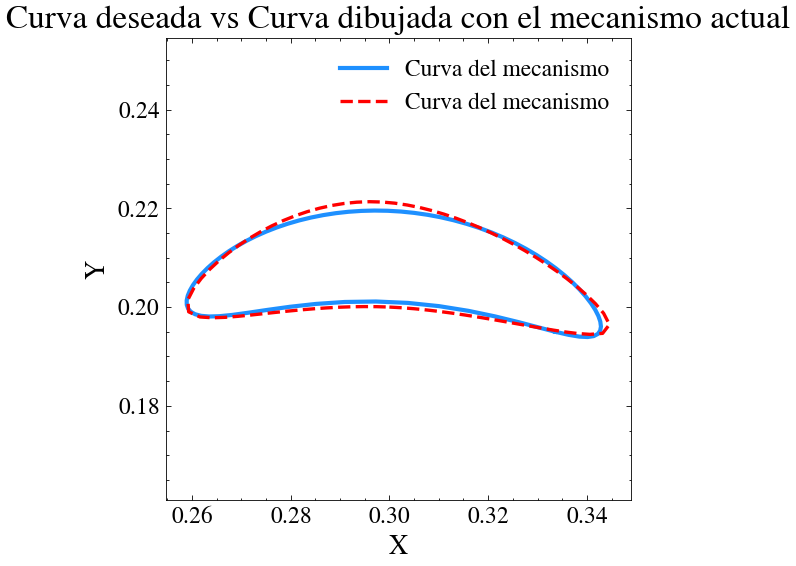

In [17]:
scaled_params2 = {k: (v * target_scale if k in keys_to_scale else v) for k, v in scaled_params1.items()}
rot_final = target_V @ normalization_info['V'].T
center_final = target_V @ center_scaled*target_scale + target_center

curve_scaled2, thetas, betas, gammas, phis  = forward_kinematics(scaled_params2, rot=rot_final, offset=center_final)
xs2_vals, ys2_vals = zip(*curve_scaled2)

xe_vals, ye_vals = zip(*evenly_spaced_points)

plt.figure(figsize=(5, 5))
#plt.plot(xb_vals, yb_vals, label='Rotated: Curva del mecanismo', color='blue')
#plt.plot(xnorm_vals, ynorm_vals, label='Curva Target', color='red')
plt.plot(xs2_vals, ys2_vals, label='Curva del mecanismo', color='dodgerblue', linewidth=2.5)
plt.plot(xe_vals, ye_vals, label='Curva del mecanismo', color='red', linewidth=2, linestyle='--')
#plt.plot(xt2_vals, yt2_vals, label='Curva del mecanismo', color='black')
plt.title("Curva deseada vs Curva dibujada con el mecanismo actual")
plt.xlabel("X")
plt.ylabel("Y")
plt.axis('equal')
plt.grid(False)
plt.legend()
plt.show()

In [20]:
coord_og = np.array([0,0])
coord_2 = np.array([best_params[x2], best_params[y2]])

coord_2t = normalization_info['V'].T @ (coord_2/normalization_info['scale'])
coord_ogt1 =  coord_og + center_scaled 
coord_2t1 = coord_2t + center_scaled 

coord_ogt2 = target_V @ (coord_ogt1*target_scale)
coord_2t2 = target_V @ (coord_2t1*target_scale)
coord_ogf = coord_ogt2 + target_center
coord_2f = coord_2t2 + target_center

<center>

#### Animación

In [21]:
v1 = coord_ogf[0]*N.x + coord_ogf[1]*N.y
r1_offset = v1 + d1*A.x
r5_offset = -coord_2f[0]*N.x - coord_2f[1]*N.y 

loop2 = (r1_offset + r2 + r3 + r4 + r5_offset).express(N)
loopx2 = loop2.dot(N.x).subs(scaled_params2).simplify().evalf()
loopy2 = loop2.dot(N.y).subs(scaled_params2).simplify().evalf()

eq_fun = smp.lambdify((theta, beta, gamma, phi), [loopx2, loopy2], "numpy")

w1 = 1  # rad/s
w2 = 1 # rad/s

tiempo_1rev_w2 = ((2 * smp.pi) / np.abs(w1)).evalf()
tiempo = np.linspace(0, float(tiempo_1rev_w2), 75)

def theta_phi_vals2(tiempo):
    theta_vals = w1 * tiempo
    phi_vals = w2 * tiempo + scaled_params2[desf]
    return theta_vals, phi_vals

theta_vals, phi_vals = theta_phi_vals2(tiempo)

def FK2(q, z0=None):
    fsolve_fun = lambda z: eq_fun(q[0], z[0], z[1], q[1])
    z0 = [np.deg2rad(80), np.deg2rad(120)] if z0 is None else z0  
    out = least_squares(fsolve_fun, z0) #bounds=([-np.pi, 0], [np.pi, np.pi]
    return out.x, out

beta_list = []
gamma_list = []

initial_guess = [np.deg2rad(80), np.deg2rad(110)]

for theta_val, phi_val in zip(theta_vals, phi_vals):
    beta_gamma, _ = FK2([theta_val, phi_val], initial_guess)
    beta_list.append(beta_gamma[0])
    gamma_list.append(beta_gamma[1])
    initial_guess = beta_gamma 

theta_array = np.array(theta_vals)
beta_array = np.array(beta_list)
gamma_array = np.array(gamma_list)
phi_array = np.array(phi_vals)

In [22]:
def components_params(vector, frame, params):
    v = [vector.dot(frame.x),vector.dot(frame.y)]
    vx = v[0].subs(params)
    vy = v[1].subs(params)
    return vx, vy

r1_num = smp.lambdify(theta, components_params(r1_offset, N, scaled_params2), "numpy")
r2_num = smp.lambdify([theta, beta], components_params(r1_offset + r2, N, scaled_params2), "numpy")
r3_num = smp.lambdify([theta, beta, gamma], components_params(r1_offset + r2 + r3, N, scaled_params2), "numpy")
r4_num = smp.lambdify([phi], components_params(-r4, N, scaled_params2), "numpy")
r6_num = smp.lambdify([theta, beta], components_params(r1_offset + r6, N, scaled_params2), "numpy")

#### Depronto es necesario cambiar ax.set_xlim o ay.set_xlim para que la animación se vea bien 

In [ ]:
x_val, y_val = coord_2f[0], coord_2f[1]

L6_x = []
L6_y = []

fig, ax = plt.subplots(figsize=(9, 5))

def update(frame):
    ax.cla()
    ax.set_xlim(0.25, 0.5)
    ax.set_ylim(0.0, 0.25)
    ax.set_xlabel("Posición en X (m)")
    ax.set_ylabel("Posición en Y (m)")
    ax.set_title("Mecanismo animado - Un ciclo entero")
    ax.grid(False)
    ax.set_aspect('equal')

    theta_val = theta_array[frame]
    beta_val = beta_array[frame]
    gamma_val = gamma_array[frame]
    phi_val = phi_array[frame]
    
    O = np.array([coord_ogf[0],coord_ogf[1]])
    L1 = np.array([r1_num(theta_val)[0], r1_num(theta_val)[1]])
    L2 = np.array([r2_num(theta_val, beta_val)[0], r2_num(theta_val, beta_val)[1]])
    L3 = np.array([r3_num(theta_val, beta_val, gamma_val)[0], r3_num(theta_val, beta_val, gamma_val)[1]])
    L4 = np.array([x_val, y_val])
    L6 = np.array([r6_num(theta_val, beta_val)[0], r6_num(theta_val, beta_val)[1]])

    L6_x.append(L6[0]) 
    L6_y.append(L6[1])

    ax.plot(xe_vals, ye_vals, 'black', linestyle='--', label="Trayectoria deseada", zorder=2, linewidth='1.5')
    ax.plot([O[0], L1[0]], [O[1], L1[1]], '-', label="r1", color="blueviolet")
    ax.plot([L1[0], L2[0]], [L1[1], L2[1]], '-')
    ax.plot([L2[0], L3[0]], [L2[1], L3[1]], '-', label="r3", color="dodgerblue")
    ax.plot([L3[0], L4[0]], [L3[1], L4[1]], '-', label="r4", color="green" )
    ax.plot([L1[0], L6[0]], [L1[1], L6[1]], '-', label="r6", color= "red")
    ax.plot(L6_x, L6_y, "orange", label="Trayectoria lograda", zorder=2, linewidth='1.25') 
    ax.legend(loc="upper left", bbox_to_anchor=(1.05, 1))

fig.subplots_adjust(right=0.7) 

frames = len(thetas)
ani = animation.FuncAnimation(fig, update, frames=frames, interval=50)

plt.close(fig)
HTML(ani.to_jshtml())